# Lab: Relationships Between Categorical Features

Imagine James Cameron has hired you to develop two character profiles for a Titanic movie reboot: one “most likely to survive” and one “least likely to survive.” Support both profiles with passenger data and visualizations, then connect them to real people and their biographies.

These labels describe profiles suggested by observed group survival percentages in this dataset. They are not guaranteed individual outcomes, a validated prediction model, or proof that any feature caused survival.


## Learning goals

- Apply the six-step analysis workflow to categorical comparisons.
- Justify categories created from age and travel-companion counts.
- Distinguish raw counts from survival percentages within groups.
- Build clearly labeled figures and check their meaning.
- Support character profiles with evidence and identify matching passengers.
- Connect data records to cited historical biographies.


## The reproducible analysis workflow

1. **Question:** What do we want to learn? +
2. **Data:** Which observations and features can help answer it?
3. **Evidence:** What should we calculate and display to answer the question?
4. **Check:** Does the result make sense in context? Do the original values support the coding and interpretation?
5. **Conclusion:** What claim is supported?
6. **Limitation:** What should we avoid concluding?

Use one six-step workflow for the complete character-profile investigation. All six feature comparisons belong together in Step 3: Evidence.


## Dataset and scope

Use the supplied `data/titanic_passengers.csv`, the 891-row training dataset from [Kaggle Titanic: Machine Learning from Disaster](https://www.kaggle.com/c/titanic/data). Each row represents a passenger in this file; it is not a complete passenger-and-crew list. Consult the source dictionary when interpreting the features.

Analyze only categorical comparisons with `Survived`. Use `Pclass` instead of `Fare`; do not analyze fare. Age is the exception: convert it to justified categories before comparing survival. Treat travel-companion counts as categories, combining sparse groups if appropriate. Use names and passenger IDs only to identify people.

| Feature | Meaning and role |
| --- | --- |
| `Survived` | Categorical outcome: 0 = did not survive, 1 = survived |
| `Pclass` | Ordered passenger class: 1, 2, or 3; categorical despite numeric storage |
| `Sex` | Recorded sex category |
| `Age` | Age in years; use only through your chosen age groups |
| `Parch` | Count of parents/children aboard; use as categories or collapse into groups |
| `SibSp` | Count of siblings/spouse aboard; use as categories or collapse into groups |
| `Embarked` | Embarkation port: C = Cherbourg, Q = Queenstown, S = Southampton |
| `Name`, `PassengerId` | Passenger identification for matching records to biographies |

The file also contains `Ticket`, `Fare`, and `Cabin`; do not use them as comparison features in this lab.


## Using AI tools responsibly

You may use AI for questions, debugging, or feedback. You remain responsible for understanding the code and checking claims against the output. Read the actual Encyclopedia Titanica biographies rather than using an uncited AI-generated fact. Disclose AI use in the final reflection.


## Step 1: Question

**Which categorical characteristics support a “most likely to survive” profile and a “least likely to survive” profile in this Titanic dataset?**

Consider age group, sex, passenger class, parents/children aboard, siblings/spouse aboard, and embarkation port together as parts of this one investigation.


**Before examining survival percentages, describe your predicted high-survival and low-survival profiles. What reasoning or prior knowledge supports your predictions?**

Your answer: 

I predict that female, children and first class passengers were the most likely to survive because the women and children were prioritized during the evacuation and the first class passengers could have had better access to the lifeboats. I predict that adult males traveling in third class were leasat likely to survive because they may have had more difficulty reaching the lifeboasts and were not given as much priority during evacuation. I will also examine whether traveling with family members and boarding at different ports were associated with survival. 


## Step 2: Data


## Load and inspect the data

Use `titanic_df` as the DataFrame name. Keep the original columns so your category choices can be checked.


In [1]:
import pandas as pd
import matplotlib.pyplot as plt


In [2]:
# Read data/titanic_passengers.csv into titanic_df.

titanic_df = pd.read_csv(r"C:\Users\maddi\Downloads\titanic_passengers.csv")

In [3]:
# Display the first five rows.

display(titanic_df.head())


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [4]:
# Display .info().

display(titanic_df.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    object 
 4   Sex          891 non-null    object 
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    object 
 11  Embarked     889 non-null    object 
dtypes: float64(2), int64(5), object(5)
memory usage: 83.7+ KB


None

In [5]:
# Display the missing-value count for each feature.

print(titanic_df.isnull().sum())

PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64


**What does one row represent? Which feature is the target, and what do its codes mean?** 

Your answer: 

Each row represents one passenger abroad the Titanic. The target feature is Survived, which indicates whether a passenger survived the disaster. A value of 0 means that the passenger did not survive, and a value of 1 means that the passenger did survive. There are 891 passengers. 


Complete this table from the inspection. Distinguish a feature's meaning from its Pandas storage type; numeric codes can represent categories.


| Feature | Data type (categorical/quantitative/identifier) | Data storage type | Missing values |
| --- | --- | --- | ---: |
| `PassengerId` | Identifier | int64  | 0 |
| `Name` | Identifier | object  | 0 |
| `Survived` | Categorical | int64 | 0 |
| `Pclass` | Categorical | int64 | 0 |
| `Sex` | Categorical  | object | 0 |
| `Age` | Quantitative | float64 | 177 |
| `Parch` | Quantitative | int64| 0 |
| `SibSp` | Quantitative | int64 | 0 |
| `Embarked` | Categorical | object | 2 |


## Plan your age groups before comparing survival

Choose your own age categories. You might use children versus adults, split at 16, 18, or 20, or define several groups such as children, teens, young adults, and older adults. There is no single required cutoff. Give a reasoned argument based on the meaning of the groups and their usefulness, not just which split produces the strongest survival difference.

Write exact boundaries, including where an age exactly at a cutoff belongs. Cover all known ages without overlapping groups. Preserve unknown ages as missing or label them “Unknown”; do not accidentally classify them as adults. If you exclude unknown ages from this comparison, state that denominator choice. Do not guess an age from whether someone survived.


| Age-group label | Exact rule (including boundary values) | Reason for this choice |
| --- | --- | --- |
| Children | Age under 13 | Children may have been prioritized during evacuation |
| Teenagers | Age 13 to under 18 | Seperates teenagers from younger children and adults |
| Adults | Age 18 to 60 | Represents the main adult population |
| Older adults | Age 60 or older | Allows comparison of older passengers |
| Unknown | Age is missing | Keeps passengers with missing ages separate |

Add rows if needed.


**Why are your age groups reasonable? How will you handle unknown ages, and why?**

Your answer:

I chose these age groups because they represent meaningful stages of life and allow me to compare survival rates among children, teenagers, adults, and older adults. Each age belongs to only on egroup. I will place passengers with missing ages into an unknown category instead of guessing their age. This will allow me to keep all 891 passengers in the analysis while identifying the 177 passengers whose ages were not recorded. 


Create `age_group` using `.loc` or `pd.cut`. If using `.loc`, initialize the column to an explicit “Unknown” label and assign labels only where ages satisfy your rules. If using `pd.cut`, choose its interval boundaries carefully and document whether intervals include their right or left endpoint. Count the observations in each category, including unknowns.


In [6]:
# Create age_group and display its category counts, including unknown ages.

titanic_df['age_group'] = 'Unknown'

titanic_df.loc[titanic_df['Age'] < 13, 'age_group'] = 'Children'
titanic_df.loc[(titanic_df['Age'] >= 13) & (titanic_df['Age'] < 18), 'age_group'] = 'Teenagers'
titanic_df.loc[(titanic_df['Age'] >= 18) & (titanic_df['Age'] < 60), 'age_group'] = 'Adults'
titanic_df.loc[titanic_df['Age'] >= 60, 'age_group'] = 'Older adults'

print(titanic_df['age_group'].value_counts())



age_group
Adults          575
Unknown         177
Children         69
Teenagers        44
Older adults     26
Name: count, dtype: int64


**Are any age groups very small? Would a different grouping be more useful? Explain any revision before comparing survival.**

Your answer:

Yes, the older adult group is relatively small, with only 26 passengers, and the teenager group has 44 passengers. These smaller groups may produce less reliable comparisons because each passenger has a greater effect on the survival percentage. However, I will keep my original age categories because they represent meaningful stages of life. I will interpret the results for smaller groups cautiously rather than changing the categories just to screate larger differences in survival rates. 

### Choose travel-companion categories

Inspect the frequencies of `Parch` and `SibSp`. Treat their values as discrete categories or collapse them into meaningful groups, such as none/any or none/one/two or more. Explain your choices, particularly when some categories have few passengers. Preserve the original columns.


In [7]:
# Display Parch and SibSp category counts; create any grouped features and display their counts.

print('Parents/Children aboard:')
print(titanic_df['Parch'].value_counts().sort_index())

print('\nSiblings/Spouse aboard:')
print(titanic_df['SibSp'].value_counts().sort_index())

titanic_df["Parch_group"] = titanic_df["Parch"].apply(
lambda x: "None" if x == 0 else "One" if x == 1 else "Two or more"
)

titanic_df["SibSp_group"] = titanic_df["SibSp"].apply(
lambda x: "None" if x == 0 else "One" if x == 1 else "Two or more"
)

print("Parch groups:")
print(titanic_df["Parch_group"].value_counts())

print("\nSibSp groups:")
print(titanic_df["SibSp_group"].value_counts())

Parents/Children aboard:
Parch
0    678
1    118
2     80
3      5
4      4
5      5
6      1
Name: count, dtype: int64

Siblings/Spouse aboard:
SibSp
0    608
1    209
2     28
3     16
4     18
5      5
8      7
Name: count, dtype: int64
Parch groups:
Parch_group
None           678
One            118
Two or more     95
Name: count, dtype: int64

SibSp groups:
SibSp_group
None           608
One            209
Two or more     74
Name: count, dtype: int64


**What travel-companion groups will you use, and why? State any exclusions and how you will handle unknown embarkation ports. Which observations form the denominator for each comparison?**

Your answer:

I will group both Parch and SibSp into three categories: none(0), one(1), and two or more(2+). THis keeps the categories meaningful while combining smaller groups into larger ones for more useful comparisons. I will preserve the original columns and include all 891 passengers in these comparisons. For embarkation ports, I will exclude the two passengers with missing values, leaving 889 passengers for that comparison. For age, I will keep missing ages in the unknown catefory. Survival percentages will be calculated using the total number of passengers in each category, including both survivors and non survivors, as the denominator. 


## Step 3: Evidence

Bring all six feature comparisons together here. For each feature:

- Display a count cross-tab with comparison categories in rows and survival outcomes in columns.
- Calculate survival percentages within each comparison group and display only the percentage who survived (column `1`). Keep group counts available for context.
- Make a bar chart of the conditional percentage who survived, with a meaningful title, descriptive axes, readable category labels, and named colors. Use a 0–100 percentage scale and `plt.legend()` if a legend is needed. Move it outside the axes if it covers the data.

Use separate code cells for the individual operations and add cells as needed. The subsections below organize the evidence; they are not separate workflows.


### Age groups

Compare `age_group` with `Survived` using your Data-step choices.


In [8]:
# Create and display the count cross-tab.

age_counts = pd.crosstab( titanic_df['age_group'], titanic_df['Survived'])
display(age_counts)

Survived,0,1
age_group,,
Adults,353,222
Children,29,40
Older adults,19,7
Teenagers,23,21
Unknown,125,52


In [9]:
# Calculate conditional percentages and display only the survived column.

age_percent = pd.crosstab(titanic_df['age_group'], titanic_df['Survived'], normalize='index') * (100)
display(age_percent[1].round(2))

age_group
Adults          38.61
Children        57.97
Older adults    26.92
Teenagers       47.73
Unknown         29.38
Name: 1, dtype: float64

For age groups, also display joint percentages (`normalize="all"`, multiplied by 100) and make a count chart showing both outcomes. Compare this with the survivor-percentage chart to distinguish counts, joint percentages, and within-group percentages.


In [10]:
# Display joint percentages, then create a count chart in a separate cell.

age_joint = pd.crosstab(titanic_df['age_group'], titanic_df['Survived'], normalize='all') * 100
display(age_joint.round(2))


Survived,0,1
age_group,,
Adults,39.62,24.92
Children,3.25,4.49
Older adults,2.13,0.79
Teenagers,2.58,2.36
Unknown,14.03,5.84


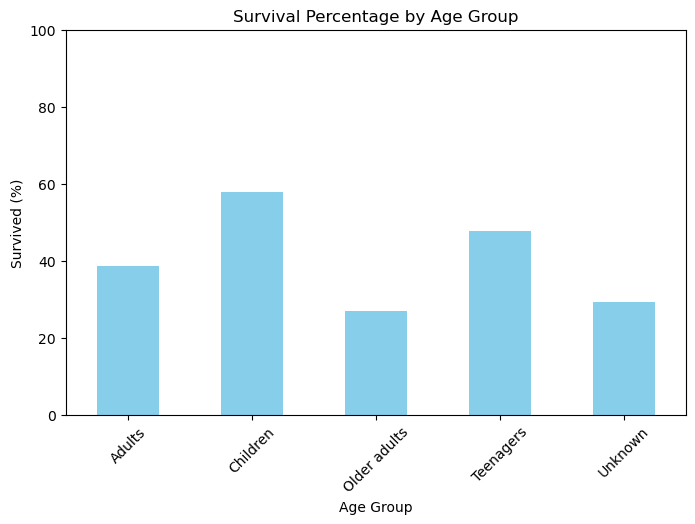

In [11]:
# Plot the conditional percentage who survived.

age_survival_pct = pd.crosstab(titanic_df['age_group'],titanic_df['Survived'], normalize='index') * 100
age_survival_pct[1].plot(kind='bar',figsize=(8, 5),color='skyblue')

plt.title('Survival Percentage by Age Group')
plt.xlabel('Age Group')
plt.ylabel('Survived (%)')
plt.ylim(0, 100)
plt.xticks(rotation=45)
plt.show()


### Sex

Compare `Sex` with `Survived` using your Data-step choices.


In [12]:
# Create and display the count cross-tab.
sex_counts = pd.crosstab(titanic_df['Sex'], titanic_df['Survived'])
display(sex_counts)


Survived,0,1
Sex,,
female,81,233
male,468,109


In [13]:
# Calculate conditional percentages and display only the survived column.
sex_pct = pd.crosstab(titanic_df['Sex'], titanic_df['Survived'], normalize='index') *100
display(sex_pct[1].round(2))

Sex
female    74.20
male      18.89
Name: 1, dtype: float64

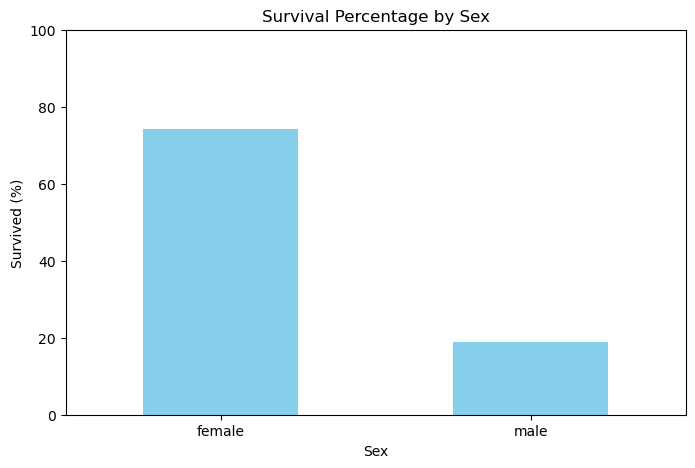

In [14]:
# Plot the conditional percentage who survived.
sex_pct[1].plot(kind='bar', color='skyblue', figsize=(8, 5))
plt.title('Survival Percentage by Sex')
plt.xlabel('Sex')
plt.ylabel('Survived (%)')
plt.ylim(0, 100)
plt.xticks(rotation=0)
plt.show()

### Passenger class

Compare `Pclass` with `Survived` using your Data-step choices.


In [15]:
# Create and display the count cross-tab.
class_counts = pd.crosstab(titanic_df['Pclass'], titanic_df['Survived'])
display(class_counts)

Survived,0,1
Pclass,,
1,80,136
2,97,87
3,372,119


In [16]:
# Calculate conditional percentages and display only the survived column.
class_pct = pd.crosstab(titanic_df['Pclass'], titanic_df['Survived'], normalize='index') * 100
display(class_pct[1].round(2))

Pclass
1    62.96
2    47.28
3    24.24
Name: 1, dtype: float64

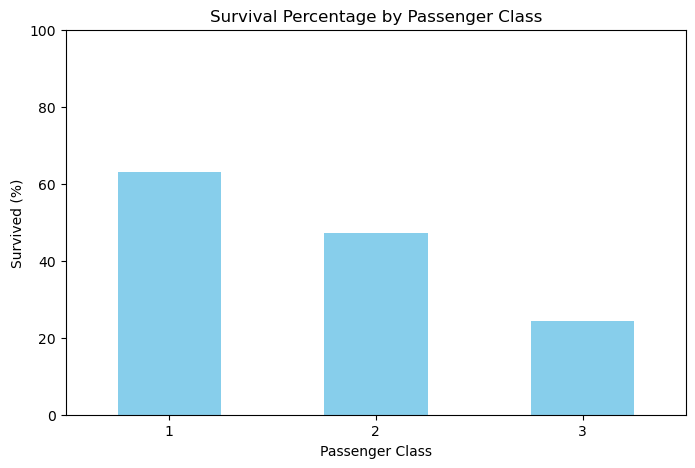

In [17]:
# Plot the conditional percentage who survived.
class_pct[1].plot(kind='bar', color='skyblue', figsize=(8, 5))
plt.title('Survival Percentage by Passenger Class')
plt.xlabel('Passenger Class')
plt.ylabel('Survived (%)')
plt.ylim(0, 100)
plt.xticks(rotation=0)
plt.show()

### Parents or children aboard

Compare `Parch or your derived group` with `Survived` using your Data-step choices.


In [18]:
# Create and display the count cross-tab.
parch_counts = pd.crosstab(titanic_df['Parch'], titanic_df['Survived'])
display(parch_counts)

Survived,0,1
Parch,,
0,445,233
1,53,65
2,40,40
3,2,3
4,4,0
5,4,1
6,1,0


In [19]:
# Calculate conditional percentages and display only the survived column.
parch_pct = pd.crosstab(titanic_df['Parch'], titanic_df['Survived'], normalize='index') * 100
display(parch_pct[1].round(2))

Parch
0    34.37
1    55.08
2    50.00
3    60.00
4     0.00
5    20.00
6     0.00
Name: 1, dtype: float64

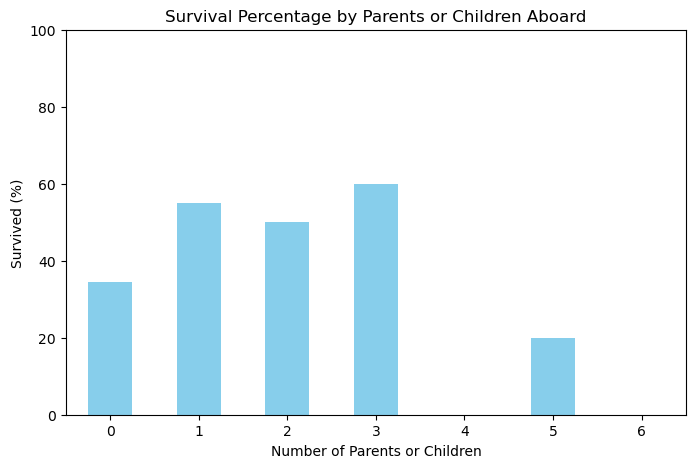

In [20]:
# Plot the conditional percentage who survived.
parch_pct[1].plot(kind='bar', color='skyblue', figsize=(8, 5))
plt.title('Survival Percentage by Parents or Children Aboard')
plt.xlabel('Number of Parents or Children')
plt.ylabel('Survived (%)')
plt.ylim(0, 100)
plt.xticks(rotation=0)
plt.show()

### Siblings or spouse aboard

Compare `SibSp or your derived group` with `Survived` using your Data-step choices.


In [21]:
# Create and display the count cross-tab.
sibsp_counts = pd.crosstab(titanic_df['SibSp'], titanic_df['Survived'])
display(sibsp_counts)

Survived,0,1
SibSp,,
0,398,210
1,97,112
2,15,13
3,12,4
4,15,3
5,5,0
8,7,0


In [22]:
# Calculate conditional percentages and display only the survived column.
sibsp_pct = pd.crosstab(titanic_df['SibSp'], titanic_df['Survived'], normalize='index') * 100
display(sibsp_pct[1].round(2))

SibSp
0    34.54
1    53.59
2    46.43
3    25.00
4    16.67
5     0.00
8     0.00
Name: 1, dtype: float64

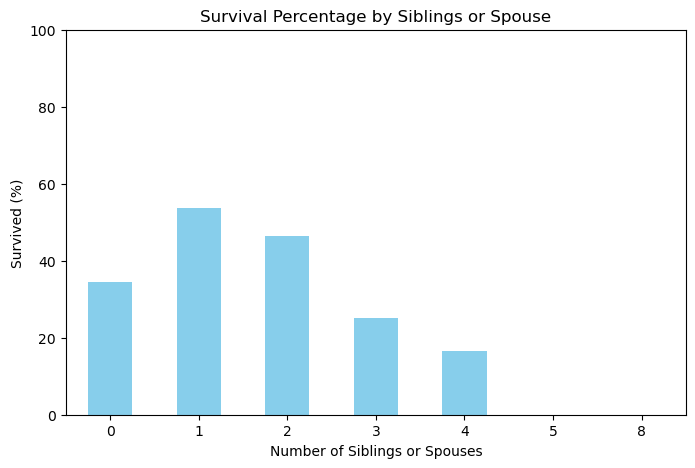

In [23]:
# Plot the conditional percentage who survived.
sibsp_pct[1].plot(kind='bar', color='skyblue', figsize=(8, 5))
plt.title('Survival Percentage by Siblings or Spouse')
plt.xlabel('Number of Siblings or Spouses')
plt.ylabel('Survived (%)')
plt.ylim(0, 100)
plt.xticks(rotation=0)
plt.show()

### Embarkation port

Compare `Embarked` with `Survived` using your Data-step choices.


In [24]:
# Create and display the count cross-tab.
embarked_counts = pd.crosstab(titanic_df['Embarked'], titanic_df['Survived'])
display(embarked_counts)

Survived,0,1
Embarked,,
C,75,93
Q,47,30
S,427,217


In [25]:
# Calculate conditional percentages and display only the survived column.
embarked_counts = pd.crosstab(titanic_df['Embarked'], titanic_df['Survived'], normalize='index') * 100
display(embarked_counts[1].round(2))

Embarked
C    55.36
Q    38.96
S    33.70
Name: 1, dtype: float64


# Plot the conditional percentage who survived.
embarked_counts[1].plot(kind='bar', color='skyblue', figsize=(8, 5))
plt.title('Survival Percentage by Embarktion Port')
plt.xlabel('Embarktion Port')
plt.ylabel('Survived (%)')
plt.ylim(0, 100)
plt.xticks(rotation=0)
plt.show()

### Summarize the evidence

Record the highest- and lowest-survival categories for each feature. Include percentages and group sizes; mention ties or very small groups that affect interpretation.


| Feature | Highest-survival category, percentage, and group size | Lowest-survival category, percentage, and group size |
| --- | --- | --- |
| Sex (example) | Female: 74.2% survived (233 of 314 passengers). | Male: 18.9% survived (109 of 577 passengers). |
| Age groups | Children: 57.97% (40 of 69 passengers) | Older adults: 26.92% (7 of 26 passengers) |
| Passenger class | 1st Class: 62.96% (136 of 216 passengers) | 3rd Class: 24.24% (119 of 491 passengers) |
| Parents or children aboard | 3: 60.0% | 4 and 6: 0.0% (0 of 4 and 0 of 1) |
| Siblings or spouse aboard | 1: 53.59% (112 of 209) | 5 and 8: 0.0% (0 of 5 and 0 of 7) |
| Embarkation port | C (Cherbourg): 55.36% (93 of 168 passengers) | S (Southampton): 33.70% (217 of 644 passengers) |


**Using the age comparison, interpret one joint percentage and one conditional percentage. What denominator does each use, and which figure answers the survival-likelihood question more clearly?**

Your answer:

The joint percentage shows that 4.49% of all 891 passengers were children who survived. The conditonal percentage shows that 57.97% of teh 69 children survived. The joint percentage uses all 891 passengers as teh denominator, while the conditional percentage answers the survival likelihood question more clearly becasue it compares survival within a specific age group.


## Step 4: Check

Check the meaning of your combined evidence, rather than repeating the initial row count or missing-value inspection.

- Compare each age group's minimum and maximum known ages with your declared boundaries, including exact cutoffs and unknown ages.
- If you collapsed travel-companion categories, cross-tab the original counts against your group labels.
- Check that percentages use all passengers in the relevant group, not just survivors. Compare the direction of the percentages with the count tables.
- Identify sparse groups or implausible values that deserve caution.


In [26]:
# Check age-group boundaries and unknown ages.
print(titanic_df.groupby('age_group')['Age'].agg(['min', 'max', 'count']))
print('\nUnknown ages:', titanic_df['Age'].isna().sum())

                min   max  count
age_group                       
Adults        18.00  59.0    575
Children       0.42  12.0     69
Older adults  60.00  80.0     26
Teenagers     13.00  17.0     44
Unknown         NaN   NaN      0

Unknown ages: 177


In [27]:
# Check travel-companion category mappings if you created grouped features.

def companion_group(n):
    if n == 0:
        return "None"
    elif n == 1:
        return "One"
    else:
        return "Two or more"

print("Parch mapping:")
display(pd.crosstab(titanic_df['Parch'], titanic_df['Parch'].apply(companion_group)))

print("SibSp mapping:")
display(pd.crosstab(titanic_df['SibSp'], titanic_df['SibSp'].apply(companion_group)))

Parch mapping:


Parch,None,One,Two or more
Parch,,,
0,678,0,0
1,0,118,0
2,0,0,80
3,0,0,5
4,0,0,4
5,0,0,5
6,0,0,1


SibSp mapping:


SibSp,None,One,Two or more
SibSp,,,
0,608,0,0
1,0,209,0
2,0,0,28
3,0,0,16
4,0,0,18
5,0,0,5
8,0,0,7


**Do the age boundaries, category mappings, and denominators match your intentions? What would make you suspicious, and did you find or correct any issues? Which small groups limit interpretation?**

Your answer:
The age boundaries match my intended groups: children under 13, teenagers 13–17, adults 18–59, and older adults 60 and above. There were 177 passengers with unknown ages. The travel-companion categories group zero as None, one as One, and two or more as Two or more. Survival percentages use the total number of passengers in each category as the denominator. I would be suspicious of percentages based on very small groups or incorrect category assignments. The groups with 4–6 parents or children and 5 or 8 siblings or spouses have very few passengers, making their survival percentages less reliable. The age-group checks found no boundary issues; the companion mappings still need to be verified.

## Step 5: Conclusion

Use the combined evidence to develop the two profiles, find matching passengers, and connect them to historical biographies.


### Build your two character profiles

Combine the evidence into a “most likely to survive” profile and a “least likely to survive” profile. Include all six elements. Cite the relevant group percentage and size for each choice. Do not multiply separate feature percentages to produce an individual survival probability: the features may be related, and separate comparisons do not establish the survival rate for their combination.


| Profile element | Most likely profile: category and evidence | Least likely profile: category and evidence |
| --- | --- | --- |
| Sex (example) | Female: 74.2% survived (233 of 314 passengers). | Male: 18.9% survived (109 of 577 passengers). |
| Age groups | Children: 57.97% (40 of 69 passengers) | Older adults: 26.92% (7 of 26 passengers) |
| Passenger class | 1st Class: 62.96% (136 of 216 passengers) |  3rd Class: 24.24% (119 of 491 passengers) |
| Parents or children aboard | 3: 60.0% | 4 and 6: 0.0% (0 of 4 and 0 of 1) |
| Siblings or spouse aboard | 1: 53.59% (112 of 209) | 5 and 8: 0.0% (0 of 5 and 0 of 7) |
| Embarkation port | C (Cherbourg): 55.36% (93 of 168 passengers | S (Southampton): 33.70% (217 of 644 passengers) |


**Write a short character description for each profile. Explain any tradeoffs where the evidence does not point to a single obvious combination.**

Your answer:
My most-likely-to-survive profile is a female child traveling in first class, with three parents or children aboard, one sibling or spouse, and departing from Cherbourg. My least-likely-to-survive profile is an older adult male traveling in third class, with four parents or children aboard, five siblings or spouses, and departing from Southampton.These profiles are based on the highest and lowest survival percentages for each individual feature. However, some categories contain very few passengers, making their percentages less reliable. The characteristics may also be related, so combining them does not guarantee an individual’s survival outcome.

### Find real passengers who fit

Use Boolean conditions with `.loc` to find passengers matching each profile across all six elements. Save the results as `most_likely_df` and `least_likely_df`, and display their names and the features used to match them. **Do not filter on `Survived` to build these lists**: an actual outcome is not a profile characteristic.

If a list is empty, explain which combination has no matching record, then revise and justify your profile transparently using the evidence. Keep all six elements in your revised profile, update the profile table, and rerun the filter. Do not silently drop a condition or invent a passenger. You need at least one matching person in each list.


In [28]:
# Create most_likely_df and display matching names and profile features.
most_likely_df = titanic_df.loc[
(titanic_df['Sex'] == 'female') &
(titanic_df['age_group'] == 'Children') &
(titanic_df['Pclass'] == 1) &
(titanic_df['Parch'] == 2) &
(titanic_df['SibSp'] == 1) &
(titanic_df['Embarked'] == 'S')
]

display(most_likely_df[
['PassengerId', 'Name', 'Sex', 'age_group',
'Pclass', 'Parch', 'SibSp', 'Embarked', 'Survived']
])
print("Matches:", len(most_likely_df))

,PassengerId,Name,Sex,age_group,Pclass,Parch,SibSp,Embarked,Survived
297,298,"Allison, Miss. Helen Loraine",female,Children,1,2,1,S,0


Matches: 1


In [29]:
# Create least_likely_df and display matching names and profile features.
least_likely_df = titanic_df.loc[
(titanic_df['Sex'] == 'male') &
(titanic_df['age_group'] == 'Older adults') &
(titanic_df['Pclass'] == 3) &
(titanic_df['Parch'] == 0) &
(titanic_df['SibSp'] == 0) &
(titanic_df['Embarked'] == 'S')
]

display(least_likely_df[
['PassengerId', 'Name', 'Sex', 'age_group',
'Pclass', 'Parch', 'SibSp', 'Embarked']
])
print("Matches:", len(least_likely_df))

,PassengerId,Name,Sex,age_group,Pclass,Parch,SibSp,Embarked
326,327,"Nysveen, Mr. Johan Hansen",male,Older adults,3,0,0,S
851,852,"Svensson, Mr. Johan",male,Older adults,3,0,0,S


Matches: 2


**How do your filters match the six profile choices? Document any revisions needed to obtain real matches.**

Your answer:
I used six characteristics for each profile: sex, age group, passenger class, parents or children, siblings or spouse, and embarkation port. The original combinations returned no matching passengers, so I revised the travel-companion counts and embarkation choices while keeping all six conditions. The least-likely profile matched two passengers. The revised most-likely profile was selected to find a real passenger while retaining the female, child, and first-class characteristics.

### Connect the records to people

Choose one person from `most_likely_df` and one from `least_likely_df`. Find each person on [Encyclopedia Titanica](https://www.encyclopedia-titanica.org/) using its passenger lists or biography search. Check identifying details to make sure you found the same person; names can have spelling variations.

For each person, select at least one interesting fact from the biography beyond the values already listed in your dataset. Describe it in your own words and link directly to the biography. Do not substitute an uncited fact or just restate survival status.


**Who did you choose from your “most likely to survive” list? Give the dataset name and PassengerId, explain how you matched the biography, describe an interesting fact, and provide the direct Encyclopedia Titanica biography URL.**

Your answer:
I chose Helen Loraine Allison, PassengerId 298. I matched her name, age, first-class status, and Southampton departure to her Encyclopedia Titanica biography. An interesting fact is that her family remained aboard while searching for her baby brother Trevor, who had been taken to a lifeboat by his nurse. Helen died in the sinking.

Biography: https://www.encyclopedia-titanica.org/titanic-victim/loraine-allison.html

**Who did you choose from your “least likely to survive” list? Give the dataset name and PassengerId, explain how you matched the biography, describe an interesting fact, and provide the direct Encyclopedia Titanica biography URL.**

Your answer:
I selected Johan Svensson, PassengerId 852, from my least-likely-to-survive list. I matched his name, third-class ticket, and Southampton departure to his Encyclopedia Titanica biography. An interesting fact is that he was traveling to South Dakota with his son after his wife died. He was reportedly reluctant to leave Sweden and was the oldest passenger aboard the Titanic.

Biography: https://www.encyclopedia-titanica.org/titanic-victim/johan-svensson.html

After choosing the people, compare their recorded survival outcomes with their profiles. A passenger can contradict a group tendency. If the biography conflicts with this dataset, report the disagreement and what the sources say rather than silently changing the data.


In [31]:
# Display the selected passengers and their recorded survival outcomes.
display(titanic_df.loc[titanic_df['PassengerId'].isin([298, 852]), ['PassengerId', 'Name', 'Survived']])

,PassengerId,Name,Survived
297,298,"Allison, Miss. Helen Loraine",0
851,852,"Svensson, Mr. Johan",0


**Did each person's actual outcome align with the profile label? What does this show about using group patterns to describe individuals? Note any discrepancies with the biographies.**

Helen Allison did not survive, even though she matched the most-likely profile. Johan Svensson also did not survive, which aligned with the least-likely profile. Both outcomes agree with their biographies. This shows that group survival patterns cannot predict every individual’s outcome, because personal circumstances and other factors also matter.

### Final recommendation to the director


**Recommend the two characters using numerical evidence and their biographical facts. How do your completed profiles compare with your initial predictions? Explain any tradeoffs or revisions.**

Your answer:
I recommend Helen Loraine Allison and Johan Svensson as contrasting characters. Helen represents a profile with favorable characteristics: females had a 74.2% survival rate, children had a 57.97% survival rate, and first-class passengers had a 62.96% survival rate. However, Helen did not survive because of the circumstances involving her family.Johan represents a less favorable profile: males had an 18.9% survival rate, older adults had a 26.92% survival rate, and third-class passengers had a 24.24% survival rate. He also died in the disaster.My initial predictions generally matched the group trends, but I revised the companion and embarkation characteristics to find actual passengers. Their stories demonstrate that statistical patterns do not guarantee individual outcomes.

## Step 6: Limitation


**What should the director avoid concluding? Discuss why separate feature comparisons do not establish an individual survival probability or causation, and address relevant limitations such as small groups, missing ages, category choices, or uncertain historical records.**

Your answer:
The director should avoid assuming that a passenger’s characteristics guarantee survival or death. The percentages show patterns between groups, but they do not prove causation or determine an individual’s survival probability. Some groups contained very few passengers, making their results less reliable. Additionally, 177 passengers had missing age information, which could affect the comparisons. The categories I created may also influence the results, and historical records may contain incomplete or inaccurate information. These limitations should be considered when interpreting the findings.

## AI-use reflection


**Did you use AI? If so, describe one suggestion you checked and accepted, modified, or rejected. If not, state that you did not use it.**

Your answer:
Yes, I used ChatGPT to help with Python code, interpreting survival percentages, and organizing my findings. One suggestion I checked was the use of Boolean conditions to identify passengers matching the survival profiles. After running the code, I found that the original profiles returned zero matches. I modified the conditions and tested them again. This helped me understand why AI-generated suggestions should be verified against actual dataset results.

## Submission checklist

- Complete one six-step workflow with an initial prediction and evidence for all six profile elements.
- Justify age boundaries and missing-age handling; use passenger class, not fare.
- Include a labeled visualization for every profile element and the age count-versus-percentage comparison.
- Support both complete profiles with group percentages and sizes.
- Display both matching-passenger lists and select one real person from each.
- Include an interesting fact and direct Encyclopedia Titanica biography link for each selected person.
- Complete the combined conclusion, limitation, and AI-use reflection.
- Restart the kernel and run all cells in order; check that claims match the output.
